# PA2 - Naive Bayes Questions

Modify this notebook so that the answers to the questions below are generated when it is executed.  You should also include markdown cells explaining or illustrating your answers where appropriate.

Name: Alex Furlich
AI Use: Claude Sonnet 5.5 on the web was used to aid in answering questions.

In [2]:
# LOAD THE DATA AND TRAIN A CLASSIFIER
from naive_bayes import NaiveBayesClassifier, load_and_process_data
X_train, y_train = load_and_process_data("data_rt_train.csv")
X_test, y_test = load_and_process_data("data_rt_test.csv")
nb_classifier = NaiveBayesClassifier()
nb_classifier.fit(X_train, y_train)

## Problem 1 - The Worst Movie

Find the most "rotten" movie review among all of the reviews in the
test set, as determined by the Naive Bayes classifier that has been
trained on the training set. You'll need to make some changes to the
code since it currently only provides a class label without returning
a score.

In [3]:
import csv

# Score every test review
rotten_scores = []
for doc in X_test:
    s = nb_classifier.score_single(doc)
    rotten_scores.append(s['0'] - s['1'])   # log-odds of rotten vs fresh

# Index of the most rotten review
worst_idx = max(range(len(rotten_scores)), key=lambda i: rotten_scores[i])

# Recover the original text for display
with open("data_rt_test.csv", encoding="utf-8") as f:
    raw_rows = [row for row in csv.reader(f) if len(row) >= 2]

print("Log-odds:", rotten_scores[worst_idx])
print("True label:", y_test[worst_idx])
print("Review:", raw_rows[worst_idx][1])

Log-odds: 13.105603042189102
True label: 0
Review: trying to figure out the rules of the country bear universe -- when are bears bears and when are they like humans , only hairier -- would tax einstein's brain . 


## Problem 2 - Probability of Rottenness 

Provide the predicted class probability distribution associated with
the following review:


```
Jurassic Park is a cautionary tale about science gone wrong and
filmmaking gone lazy. For all its groundbreaking effects, the plot is
held together with dino-sized leaps in logic and characters who make
decisions so dumb they deserve to be eaten. The kids are annoying, the
adults are incompetent, and Jeff Goldblum spends half the movie
shirtless and smirking like he’s in a cologne ad. It’s less a
thrilling adventure and more a theme park ride with a script written
on the back of a napkin.
```

Again, you will need to modify the existing classifier to convert the
log-based scores to a normalized probability distribution.

*Hint:* the log scores get more negative with every word, and
`math.exp` of anything below about -745 underflows to 0.  To avoid
this, subtract the largest class score from every class score before
exponentiating.  This rescales all of the scores by the same factor,
which cancels out when you normalize.

In [4]:
from naive_bayes import tokenize_text

review = """Jurassic Park is a cautionary tale about science gone wrong and
filmmaking gone lazy. For all its groundbreaking effects, the plot is
held together with dino-sized leaps in logic and characters who make
decisions so dumb they deserve to be eaten. The kids are annoying, the
adults are incompetent, and Jeff Goldblum spends half the movie
shirtless and smirking like he’s in a cologne ad. It’s less a
thrilling adventure and more a theme park ride with a script written
on the back of a napkin."""

tokens = tokenize_text(review)
probs = nb_classifier.predict_proba_single(tokens)

print("P(rotten) =", probs['0'])
print("P(fresh)  =", probs['1'])
print("Sum:", sum(probs.values()))   # sanity check: should be 1.0

P(rotten) = 0.9998419811896502
P(fresh)  = 0.00015801881034984086
Sum: 1.0


## Problem 3 - ROC Curve

Generate an ROC curve using the provided test data, where "fresh"
is the positive class. This will require determining a score value for
every test instance. You should make use of the [sklearn ROC curve
function](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
in generating your figure.

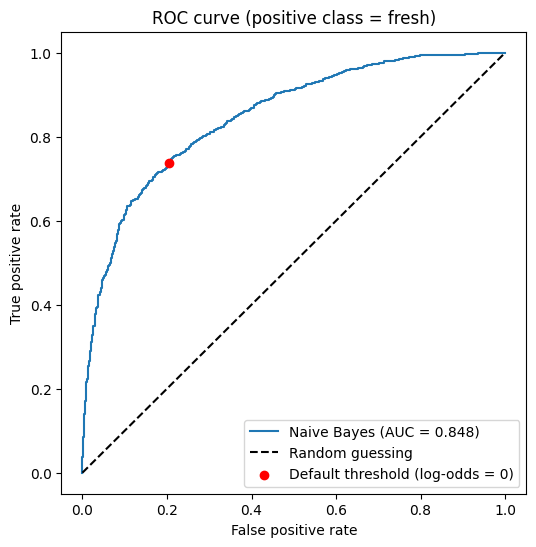

In [5]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# PROBLEM 3: score = log-odds of fresh vs. rotten for each test review
y_true = [1 if y == '1' else 0 for y in y_test]
y_score = []
for doc in X_test:
    s = nb_classifier.score_single(doc)
    y_score.append(s['1'] - s['0'])

fpr, tpr, thresholds = roc_curve(y_true, y_score)
auc = roc_auc_score(y_true, y_score)

# Where the classifier's default decision rule (threshold 0) lands on the curve
default_idx = max(i for i, t in enumerate(thresholds) if t >= 0)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.scatter(fpr[default_idx], tpr[default_idx], color="red", zorder=5,
            label="Default threshold (log-odds = 0)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (positive class = fresh)")
plt.legend()
plt.show()

## Problem 4 - Predictive Words

Find the 10 words that, after training, are most indicative of
rottenness, and the 10 words that are most indicative of freshness.

Answering this requires understanding how class scores are calculated
by the classifier:

```python
        # Calculate scores for each class
        for class_label in self.classes:
            # Start with log of class prior
            log_prob = math.log(self.class_priors[class_label])

            # Add log probabilities of known words
            for word in known_words:
                word_prob = self.word_probs[class_label][word]
                log_prob += math.log(word_prob)                  # <------

            class_scores[class_label] = log_prob
```

The indicated line can be seen as a weighted vote associated with one
of the words in the review.  If the word is more associated with one
class than the other, it will have a relatively higher value.  The
most telling words are the words whose *log* class conditional
probabilities differ the most between the two classes.

In [6]:
import math

# Positive = indicative of rotten ('0'), negative = indicative of fresh ('1').
word_scores = {
    w: math.log(nb_classifier.word_probs['0'][w]) - math.log(nb_classifier.word_probs['1'][w])
    for w in nb_classifier.vocabulary
}

ranked = sorted(word_scores, key=word_scores.get)   # most fresh ... most rotten

top_rotten = ranked[::-1][:10]
top_fresh = ranked[:10]

print(f"{'Most rotten':<20}{'score':>8}{'rotten ct':>11}{'fresh ct':>10}")
for w in top_rotten:
    print(f"{w:<20}{word_scores[w]:>8.2f}{nb_classifier.word_counts['0'][w]:>11}{nb_classifier.word_counts['1'][w]:>10}")

print()
print(f"{'Most fresh':<20}{'score':>8}{'rotten ct':>11}{'fresh ct':>10}")
for w in top_fresh:
    print(f"{w:<20}{word_scores[w]:>8.2f}{nb_classifier.word_counts['0'][w]:>11}{nb_classifier.word_counts['1'][w]:>10}")

Most rotten            score  rotten ct  fresh ct
unfunny                 3.18         23         0
badly                   3.00         19         0
poorly                  2.84         16         0
shoot                   2.71         14         0
plodding                2.64         13         0
disguise                2.64         13         0
bore                    2.64         13         0
boring                  2.64         41         2
product                 2.57         12         0
tiresome                2.57         12         0

Most fresh             score  rotten ct  fresh ct
engrossing             -3.17          0        23
riveting               -2.77          0        15
wonderful              -2.60          1        26
spare                  -2.56          0        12
vividly                -2.56          0        12
tour                   -2.56          0        12
gem                    -2.56          0        12
heartwarming           -2.48          0        11

## Problem 5 - Laplace Smoothing

The classifier estimates word probabilities using Laplace smoothing.
The formula from the slides,

$$P(X_i = x \mid Y = y) = \frac{\text{count}(X_i = x, Y = y) + 1}{\text{count}(Y = y) + |V_i|},$$

was written for attributes like *Golf* or *Fedora*, where each
attribute has its own small set of possible values.  Our text
classifier instead has a single attribute, "which word," whose
possible values are the words in the vocabulary $V$.  Each word in a
review is treated as an independent observation of that attribute,
drawn from the same class-specific distribution no matter where in the
review it appears (so shuffling a review's words would not change its
score).  Adapted to that setting, the formula becomes

$$P(w \mid Y = y) = \frac{\text{count}(w, y) + \alpha}{N_y + \alpha |V|}$$

where $\text{count}(w, y)$ is the number of times word $w$ appears in
training reviews of class $y$, $N_y$ is the total number of words in
training reviews of class $y$, and $\alpha$ is the number of extra
times we pretend to have seen each word.  Standard Laplace smoothing
uses $\alpha = 1$, which is the classifier's default.  The raw counts
are stored in the classifier's `word_counts` and `total_words`
attributes.

a) Find the word that appears most often in rotten training reviews
but never appears in fresh ones.  Report how many times it appears in
rotten reviews, and the smoothed probability that the classifier
assigns to it for each class.

b) Without smoothing, what would $P(w \mid \text{fresh})$ be for your
word from part (a), and what would that do to the fresh score of any
review containing it?  An earlier version of this classifier had no
smoothing.  To avoid taking the log of zero, it simply ignored every
word that had a count of zero in either class.  How many test reviews
contain at least one word that it would have ignored?  Explain why
ignoring these words is a poor fix, using your word from part (a) as
an example.

c) The `alpha` argument to the constructor controls the strength of
the smoothing.  Plot test accuracy as a function of `alpha` for values
from 0.01 to 1,000,000, using a log scale for the x-axis.  What happens
to the classifier's predictions when `alpha` is very large, and why?

Word: unfunny
Count in rotten reviews: 23
P(word | rotten): 0.0002989313205291084
P(word | fresh):  1.2405870457900679e-05
0.0002989313205291084
1.2405870457900679e-05
10201 of 16239 vocabulary words have a zero count in one class
1498 of 2134 test reviews contain at least one


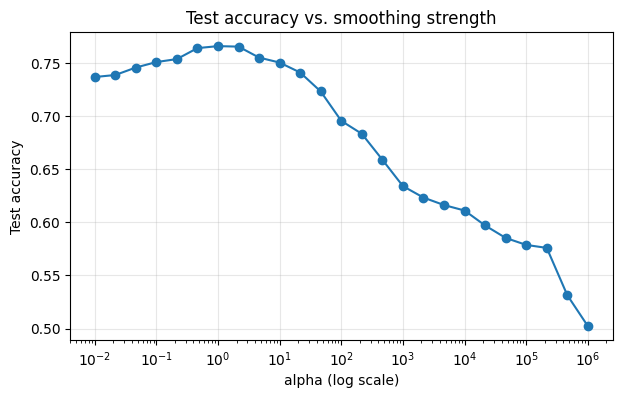

Counter({'0': 2125, '1': 9})
Counter({'0': 4269, '1': 4260})


In [7]:
# PROBLEM 5a
rot = nb_classifier.word_counts['0']
fresh = nb_classifier.word_counts['1']

rotten_only = [w for w in rot if fresh[w] == 0]
best = max(rotten_only, key=lambda w: rot[w])

V = len(nb_classifier.vocabulary)
print("Word:", best)
print("Count in rotten reviews:", rot[best])
print("P(word | rotten):", nb_classifier.word_probs['0'][best])
print("P(word | fresh): ", nb_classifier.word_probs['1'][best])

# Check against the formula (count + alpha) / (N_y + alpha * |V|)
a = nb_classifier.alpha
print((rot[best] + a) / (nb_classifier.total_words['0'] + a * V))
print((0 + a) / (nb_classifier.total_words['1'] + a * V))


# PROBLEM 5b: words the old (unsmoothed) classifier would have ignored
vocab = nb_classifier.vocabulary
zero_words = {w for w in vocab if rot[w] == 0 or fresh[w] == 0}

n_affected = sum(any(w in zero_words for w in doc) for doc in X_test)
print(f"{len(zero_words)} of {len(vocab)} vocabulary words have a zero count in one class")
print(f"{n_affected} of {len(X_test)} test reviews contain at least one")


import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import accuracy_score
from naive_bayes import NaiveBayesClassifier

# PROBLEM 5c
alphas = np.logspace(-2, 6, 25)     # 0.01 to 1,000,000
accs = []
for a in alphas:
    clf = NaiveBayesClassifier(alpha=a)
    clf.fit(X_train, y_train)
    accs.append(accuracy_score(y_test, clf.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, accs, marker="o")
plt.xlabel("alpha (log scale)")
plt.ylabel("Test accuracy")
plt.title("Test accuracy vs. smoothing strength")
plt.grid(True, alpha=0.3)
plt.show()

# Evidence for the explanation: what does the biggest-alpha classifier predict?
print(Counter(clf.predict(X_test)))
print(Counter(y_train))

As the alpha grows it becomes a domineering force in the calculations like count + alpha and N + alpha*|V|. This equalized the likelihoods for words turning prediction back to coin flip level accuracy.

## Problem 6 - Writing Deceptive Reviews

Write a **positive** movie review that will be classified as **highly negative** by
our trained classifier.  Provide your review as well as the
probability distribution (using the same approach as Problem 2).

In [9]:
review = """This movie is a truly wonderful gem engrossing at introducing viewers on how to create heartbreaking mediocrity in film. It’s tour of how film should not be made. I find it almost riveting how confusing the plot is with no spare room every minute is packed in discombobulated detail."""

tokens = tokenize_text(review)
known = [w for w in tokens if w in nb_classifier.vocabulary]

# Per-word contribution to log-odds (positive = pushes rotten)
for w in known:
    print(f"{w:<15}{word_scores[w]:>7.2f}")

probs = nb_classifier.predict_proba_single(tokens)
print("P(rotten) =", probs['0'])
print("P(fresh)  =", probs['1'])

this              0.17
movie             0.40
truly            -0.18
wonderful        -2.60
gem              -2.56
engrossing       -3.17
introducing       0.00
viewers           0.43
how               0.17
create            0.00
heartbreaking    -2.48
mediocrity        1.80
film             -0.25
tour             -2.56
how               0.17
film             -0.25
should            0.55
not               0.25
made              0.18
find              0.09
almost            0.35
riveting         -2.77
how               0.17
confusing         0.47
the               0.02
plot              0.70
with             -0.25
spare            -2.56
room              0.34
every             0.44
minute            0.55
packed           -0.22
detail           -1.09
P(rotten) = 1.1673937835516137e-06
P(fresh)  = 0.9999988326062165
